In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data.csv")
df["scenario"] = df["scenario"].astype(str).str.strip()
data = df[df["scenario"] == "02_MonthlySales"].copy()
print(data.shape)
data.head()

(12, 8)


,dataset_id,scenario,student_id,study_hours,prep_course,exam_score,stress_level,school_type
10,DS2,02_MonthlySales,M001,2023-01,TechStore,12000,150,TechStore
11,DS2,02_MonthlySales,M002,2023-02,TechStore,14500,160,TechStore
12,DS2,02_MonthlySales,M003,2023-03,TechStore,13000,155,TechStore
13,DS2,02_MonthlySales,M004,2023-04,TechStore,18000,190,TechStore
14,DS2,02_MonthlySales,M005,2023-05,TechStore,21000,210,TechStore


### Prepare data

In [2]:
data["month"] = pd.to_datetime(data["study_hours"]).dt.to_period("M")
data["revenue"] = pd.to_numeric(data["exam_score"], errors="coerce")

pivot = (data.groupby(["month", "school_type"])["revenue"]
             .mean()
             .unstack("school_type")
             .sort_index())
pivot.index = pivot.index.strftime("%b")   # Jan, Feb, ... Jun
pivot

school_type,ApparelCo,TechStore
month,,
Jan,8000.0,12000.0
Feb,9500.0,14500.0
Mar,11000.0,13000.0
Apr,10500.0,18000.0
May,13000.0,21000.0
Jun,15000.0,19500.0


### Line chart

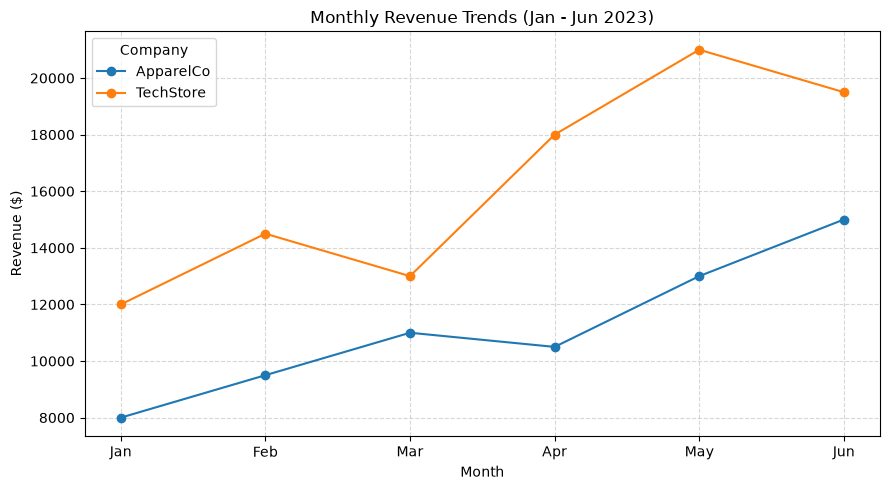

In [3]:
plt.figure(figsize=(9, 5))

for company in pivot.columns:
    plt.plot(pivot.index, pivot[company], marker="o", label=company)

plt.title("Monthly Revenue Trends (Jan - Jun 2023)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.legend(title="Company")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()